# Parte 3 · Optimismo simulado y out-of-bag (3.4, 3.5 y 3.6)

**Autor:** Gregorio Coronel · Grupo Taiwan

**Declaración de uso de IA:** se utilizó Claude (Anthropic) como herramienta de apoyo para comprender lo que pedía cada inciso del enunciado y como asistencia al escribir y depurar el código. El análisis, la verificación de resultados y su interpretación fueron revisados por el autor.

Datos: Taiwan, variables estandarizadas con `cargar_taiwan`. Los hiperparámetros se leen de `resultados/hiperparametros.json` y las curvas de 3.2 de `resultados/parte3_error_flexibilidad.csv` (notebook 05), así que este notebook va después del 05.

In [1]:
import sys, json
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from datos import cargar_taiwan
from flexibilidad import diagonal_knn, espectro_centrado, traza_ridge
from optimismo import simular_optimismo

X_train, X_test, y_train, y_test, sd = cargar_taiwan("../data/taiwan_credit.csv")
hp = json.load(open("../resultados/hiperparametros.json"))
mse = lambda y, p: np.mean((y - p) ** 2)
hp

{'lambda': 316.2278, 'k': 50, 'max_depth': 4, 'min_samples_leaf': 50}

## 3.4 · Simulación del optimismo

En datos reales no hay $y$ nuevas en los mismos $x$, así que se fabrican:

1. $X$ fija: una submuestra de 3 000 filas del entrenamiento (semilla 0).
2. La "verdad" $f$ son las predicciones de un bosque con `min_samples_leaf=10` ajustado a las $y$ reales de esas filas, y $\sigma$ es su RMSE out-of-bag. Para tener out-of-bag el bosque necesita `bootstrap=True` (el bosque del resto del proyecto usa `bootstrap=False`).
3. En cada réplica $b = 1, \dots, 50$ (semilla $b$): $y = f + \sigma\varepsilon$ y $y_{\text{nueva}} = f + \sigma\varepsilon'$ con $\varepsilon, \varepsilon' \sim N(0, 1)$. Se ajusta el modelo con $y$ y el optimismo de la réplica es $\frac1n\sum_i (y_{\text{nueva},i} - \hat y_i)^2 - \frac1n\sum_i (y_i - \hat y_i)^2$.

La función está en `src/optimismo.py`.

In [2]:
rng = np.random.default_rng(0)
pos = np.sort(rng.choice(len(X_train), 3000, replace=False))
X, y_real = X_train.iloc[pos], y_train[pos]
n = len(X)

verdad = RandomForestRegressor(n_estimators=200, min_samples_leaf=10, max_features=0.33,
                               oob_score=True, random_state=0, n_jobs=-1).fit(X, y_real)
f = verdad.predict(X)
sigma = np.sqrt(mse(y_real, verdad.oob_prediction_))
print(f"n = {n}, filas repetidas en X: {X.duplicated().sum()}")
print(f"f entre {f.min():.3f} y {f.max():.3f}, σ = RMSE out-of-bag = {sigma:.4f}, σ² = {sigma**2:.4f}")

n = 3000, filas repetidas en X: 0
f entre 0.001 y 0.859, σ = RMSE out-of-bag = 0.3710, σ² = 0.1377


In [3]:
modelos = {
    "k-NN (k = 5)": KNeighborsRegressor(n_neighbors=5),
    "k-NN (k = 30)": KNeighborsRegressor(n_neighbors=30),
    f"Ridge (λ = {hp['lambda']:g})": Ridge(alpha=hp["lambda"]),
    "Árbol (prof. 6)": DecisionTreeRegressor(max_depth=6, random_state=0),
    "Árbol (prof. 10)": DecisionTreeRegressor(max_depth=10, random_state=0),
}

filas, simulados = [], {}
for nombre, modelo in modelos.items():
    opt, hojas = simular_optimismo(modelo, X, f, sigma, replicas=50)
    simulados[nombre] = opt
    if isinstance(modelo, KNeighborsRegressor):
        traza = diagonal_knn(modelo, X)[0].sum()      # S_ii = 1/k si la fila es su propio vecino
    elif isinstance(modelo, Ridge):
        traza = traza_ridge(espectro_centrado(X), hp["lambda"])
    else:
        traza = hojas.mean()                          # tr(S) = hojas; cambia con cada réplica
    filas.append({"modelo": nombre, "optimismo simulado": opt.mean(), "error estándar": opt.std(ddof=1) / np.sqrt(len(opt)),
                  "tr(S)": traza, "2σ²tr(S)/n": 2 * sigma**2 * traza / n,
                  "hojas (mín–máx)": f"{hojas.min()}–{hojas.max()}" if len(hojas) else ""})

tabla = pd.DataFrame(filas).set_index("modelo")
tabla["simulado / fórmula"] = tabla["optimismo simulado"] / tabla["2σ²tr(S)/n"]
tabla["dif. en errores estándar"] = (tabla["optimismo simulado"] - tabla["2σ²tr(S)/n"]) / tabla["error estándar"]
tabla.to_csv("../resultados/parte3_optimismo_simulado.csv")
tabla.round(4)

,optimismo simulado,error estándar,tr(S),2σ²tr(S)/n,hojas (mín–máx),simulado / fórmula,dif. en errores estándar
modelo,,,,,,,
k-NN (k = 5),0.0558,0.0007,600.0000,0.0551,,1.0131,1.0593
k-NN (k = 30),0.0099,0.0006,100.0000,0.0092,,1.0790,1.1333
Ridge (λ = 316.228),0.0025,0.0007,17.8555,0.0016,,1.4997,1.0926
Árbol (prof. 6),0.0299,0.0007,60.4200,0.0055,54–64,5.4016,37.2667
Árbol (prof. 10),0.1018,0.0013,428.9200,0.0394,340–491,2.5865,48.0006


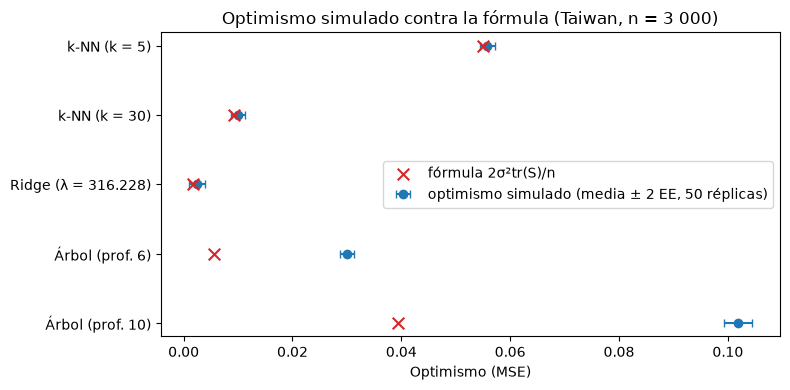

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
y_pos = np.arange(len(tabla))[::-1]
ax.errorbar(tabla["optimismo simulado"], y_pos, xerr=2 * tabla["error estándar"], fmt="o", capsize=3,
            label="optimismo simulado (media ± 2 EE, 50 réplicas)")
ax.scatter(tabla["2σ²tr(S)/n"], y_pos, marker="x", s=70, color="tab:red", zorder=3, label="fórmula 2σ²tr(S)/n")
ax.set_yticks(y_pos, tabla.index)
ax.set(xlabel="Optimismo (MSE)", title="Optimismo simulado contra la fórmula (Taiwan, n = 3 000)")
ax.legend(loc="center right")
plt.tight_layout()
plt.savefig("../figs/parte3_optimismo_simulado.png", dpi=150)
plt.show()

> **Pregunta 3.4.** ¿Para cuáles modelos cuadra la fórmula $2\sigma^2\,\text{tr}(S)/n$ y para cuáles no? ¿Por qué?

**Cuadra en k-NN y en ridge.** Con $k = 5$ el optimismo simulado es $0.0558 \pm 0.0007$ y la fórmula da $0.0551$; con $k = 30$, $0.0099 \pm 0.0006$ contra $0.0092$; en ridge, $0.0025 \pm 0.0007$ contra $0.0016$. Las tres diferencias son de un error estándar. Que las tres queden del mismo lado no es un sesgo de la fórmula: las 50 réplicas usan las mismas semillas en todos los modelos, así que comparten el mismo ruido. En k-NN no hay filas repetidas en la submuestra, cada fila es su propio vecino más cercano y $\text{tr}(S) = n/k$ exacto (600 y 100). En ridge $\text{tr}(S) = 17.9$ y no $p + 1 = 24$, porque $\lambda \approx 316$ encoge más con 3 000 filas que con 24 000.

**No cuadra en los árboles.** Con profundidad 6 el optimismo simulado es $0.0299$ y la fórmula da $0.0055$ (5.4 veces menos); con profundidad 10, $0.1018$ contra $0.0394$ (2.6 veces menos). Las diferencias son de más de 37 errores estándar.

**Por qué.** La fórmula sale de $\text{Cov}(\hat y_i, y_i) = \text{Cov}\big(\sum_j S_{ij} y_j,\, y_i\big) = S_{ii}\,\sigma^2$, y ese paso solo vale si $S$ es fija, es decir, si no depende de $y$.

- En k-NN los vecinos se escogen solo con las distancias entre las $x$, y en ridge $S = \frac1n\mathbf 1\mathbf 1^\top + X_c(X_c^\top X_c + \lambda I)^{-1}X_c^\top$ solo depende de $X$ y de $\lambda$. Como $X$ es la misma en las 50 réplicas, $S$ es la misma matriz en todas y lo único que cambia es $y$.
- En un árbol, $S_{ij} = 1/n_{\text{hoja}}$ si $x_i$ y $x_j$ caen en la misma hoja, pero las hojas salen de los cortes, y los cortes se escogen **mirando $y$** para bajar el error de entrenamiento. Por eso $S$ cambia de réplica en réplica: el número de hojas va de 54 a 64 con profundidad 6 y de 340 a 491 con profundidad 10. El árbol pone cortes justo donde el ruido de esa réplica hace parecer que hay una diferencia, así que $\hat y_i$ sigue a $y_i$ más de lo que dice $S_{ii}$: la covarianza real es mayor que $S_{ii}\sigma^2$ y el optimismo también.

Contar las hojas solo mide los grados de libertad de promediar dentro de cada hoja, no los de haber escogido los cortes (la variable y el umbral de cada nodo). Por eso el árbol de profundidad 6, con unas 60 hojas, tiene un optimismo 5 veces mayor que la fórmula: cada corte es una búsqueda entre 23 variables y miles de umbrales.

## 3.5 · Brecha prueba − entrenamiento en los datos reales

Se toman de las curvas de 3.2 (Jorge) las mismas configuraciones de 3.4, ajustadas con las 24 000 filas reales, y se compara la brecha $\text{MSE}_{\text{prueba}} - \text{MSE}_{\text{entrenamiento}}$ con la fórmula $2\sigma^2\,\text{tr}(S)/n$ evaluada con $n = 24\,000$ y la traza que reporta 3.2. Para $\sigma^2$ se usa el mismo valor de 3.4.

In [5]:
curvas = pd.read_csv("../resultados/parte3_error_flexibilidad.csv")
config = {"k-NN (k = 5)": ("k-NN", 5), "k-NN (k = 30)": ("k-NN", 30), f"Ridge (λ = {hp['lambda']:g})": ("Ridge", hp["lambda"]),
          "Árbol (prof. 6)": ("Árbol", 6), "Árbol (prof. 10)": ("Árbol", 10)}

filas = []
for nombre, (familia, valor) in config.items():
    fila = curvas[(curvas.familia == familia) & np.isclose(curvas.valor_parametro, valor, rtol=1e-6)]
    assert len(fila) == 1, nombre
    fila = fila.iloc[0]
    filas.append({"modelo": nombre, "MSE entrenamiento": fila.mse_train, "MSE prueba": fila.mse_test,
                  "brecha prueba − entr.": fila.mse_test - fila.mse_train, "tr(S) (n = 24 000)": fila.traza,
                  "2σ²tr(S)/n (n = 24 000)": 2 * sigma**2 * fila.traza / fila.n_train,
                  "optimismo simulado (n = 3 000)": tabla.loc[nombre, "optimismo simulado"]})
brecha = pd.DataFrame(filas).set_index("modelo")
brecha.round(4)

,MSE entrenamiento,MSE prueba,brecha prueba − entr.,tr(S) (n = 24 000),2σ²tr(S)/n (n = 24 000),optimismo simulado (n = 3 000)
modelo,,,,,,
k-NN (k = 5),0.1083,0.1590,0.0507,4800.0000,0.0551,0.0558
k-NN (k = 30),0.1328,0.1396,0.0068,800.0000,0.0092,0.0099
Ridge (λ = 316.228),0.1517,0.1479,-0.0038,22.4171,0.0003,0.0025
Árbol (prof. 6),0.1327,0.1345,0.0019,62.0000,0.0007,0.0299
Árbol (prof. 10),0.1163,0.1485,0.0322,393.0000,0.0045,0.1018


In [6]:
print(f"Tasa de mora: entrenamiento {y_train.mean():.4f}, prueba {y_test.mean():.4f}")
print(f"MSE de predecir la media de entrenamiento: en entrenamiento {mse(y_train, y_train.mean()):.4f}, en prueba {mse(y_test, y_train.mean()):.4f}")

Tasa de mora: entrenamiento 0.2225, prueba 0.2162
MSE de predecir la media de entrenamiento: en entrenamiento 0.1730, en prueba 0.1695


> **Pregunta 3.5.** ¿La brecha entre prueba y entrenamiento en los datos reales es lo mismo que el optimismo? ¿Qué más se mete en esa brecha?

No. El optimismo compara el error en **los mismos** $x_i$ con $y$ nuevas, y la brecha compara el entrenamiento con **otras** $x$. En la tabla:

- k-NN: brecha de $0.0507$ ($k = 5$) y $0.0068$ ($k = 30$) contra $0.0551$ y $0.0092$ de la fórmula. Se parecen, pero no son iguales. (La columna simulada con $n = 3\,000$ solo es comparable aquí, porque en k-NN $\text{tr}(S)/n = 1/k$ no depende de $n$.)
- Ridge: la brecha es **negativa**, $-0.0038$: el error de prueba es menor que el de entrenamiento. Un optimismo no puede ser negativo, así que eso ya no es optimismo.
- Árboles: brecha de $0.0019$ (prof. 6) y $0.0322$ (prof. 10) contra $0.0007$ y $0.0045$ de la fórmula, que en 3.4 ya vimos que se queda corta.

Lo que se mete en la brecha:

1. **Los $x$ de prueba no son los de entrenamiento.** En una fila de entrenamiento el modelo ya la tenía: en k-NN la fila es uno de sus propios vecinos y aporta $1/k$ de su propia $y$; en un árbol cae en una hoja que se armó con ella. En una fila de prueba no existe ese voto propio, el vecindario o la hoja son de otros clientes y entran el sesgo y la varianza del modelo en un punto nuevo.
2. **La muestra de prueba es una sola y tiene su propio ruido.** Esta prueba es un poco "más fácil": la mora es 0.2162 contra 0.2225 en entrenamiento, y solo predecir la media da un MSE de 0.1695 en prueba contra 0.1730 en entrenamiento. Esa diferencia de $-0.0035$ afecta a todos los modelos y, sola, explica casi toda la brecha negativa de ridge ($-0.0038 + 0.0035 \approx -0.0003$, del orden de la fórmula, $0.0003$). Con la misma corrección k-NN queda en $0.054$ y $0.010$, más cerca de la fórmula.
3. **Las $y$ reales son 0/1**, así que $\text{Var}(y_i) = p_i(1 - p_i)$ cambia con $x$, y la fórmula supone una $\sigma^2$ constante.
4. **En los árboles**, la parte adaptativa de 3.4: la brecha de prof. 10 es 7 veces la fórmula.

En resumen: brecha = optimismo + (error en $x$ nuevas − error en las $x$ de entrenamiento) + ruido de la partición. El optimismo es solo una parte.